# Q10. Which brain area has the shortest intrinsic neuronal timescale during baseline activity?

**Intrinsic timescale** is how long a neuron's spontaneous fluctuations persist. If a unit happens to fire more than usual now, how long does it stay elevated?
The standard measure comes from Murray et al. (2014, *Nature Neuroscience*):

1. **Baseline window:** the **1 s before stimulus onset** in every trial, keeping only trials where that whole second falls after the previous trial ended (no stimulus, no outcome).
2. Count each unit's spikes in **50-ms bins**, which gives 20 bins per trial.
3. **Autocorrelation across trials:** for each pair of bins i and i+k, correlate the counts across trials, then average over i. If a unit is "high" in bin i of a trial, is it still high k bins later in that same trial?
4. Fit an exponential, **R(k) = A·(exp(−k·50 ms / τ) + B)**, starting at the largest of the first lags, since the very first lags can be lowered by refractoriness. **τ** is the intrinsic timescale.

As in Murray et al., each **mouse and area gets one fit**, on the mean autocorrelation of its units (units with baseline rate ≥ 1 Hz, whose autocorrelation is less noisy). This gives 18 values per area.

**Robustness checks:**
- a window in the inter-trial interval (0.8 s before trial start);
- other rate cutoffs;
- separate fits for each unit.

The code lives in `c2p/q10_timescales.py`. The fitting was checked on synthetic data: a true τ of 150 ms gave 136 ms.

In [1]:
import sys; sys.path.insert(0, "..")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats as sps

from c2p import AREAS, AREA_COLORS, RESULTS_DIR
from c2p import q10_timescales as q
from c2p.stats import area_bootstrap, per_mouse_tests

units, acfs = q.compute()                  # cached; q.compute(force=True) recomputes (~5 min)
pop = q.population_taus(units, acfs, "pre1s")
taus = pop.pivot(index="mouse", columns="area", values="tau_ms")
lags_ms = np.arange(1, 20) * 50
print(f"trials per mouse with a clean 1-s baseline: {units[units.window == 'pre1s'].groupby('mouse').n_trials.first().describe()[['min', '50%', 'max']].to_dict()}")
print(f"units with baseline rate ≥ {q.MIN_RATE} Hz: {pop.groupby('area').n_units.sum().to_dict()}; median fit R² = {pop.r2.median():.2f}")

trials per mouse with a clean 1-s baseline: {'min': 408.0, '50%': 538.0, 'max': 994.0}
units with baseline rate ≥ 1.0 Hz: {1: 604, 2: 356, 3: 286}; median fit R² = 0.94


## 1. The autocorrelation and its decay

The left panel shows the mean autocorrelation of each area (averaged over mice; the dots are data) together with the exponential fitted to that average.
The right panels show every mouse. A faster decay means a shorter timescale.

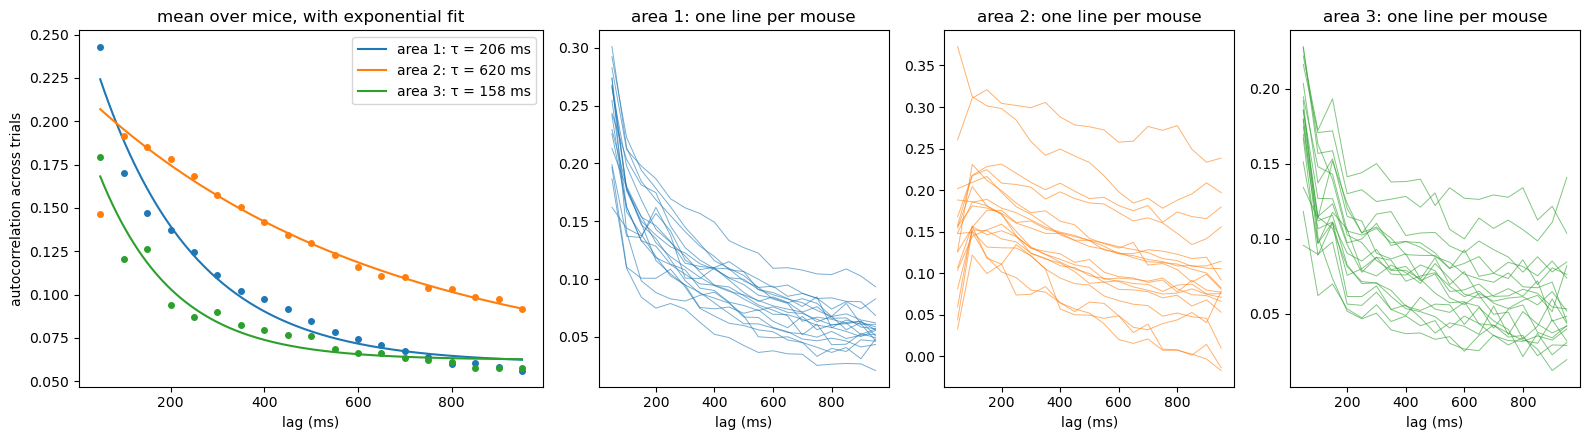

In [2]:
fig = plt.figure(figsize=(16, 4.5))
gs = fig.add_gridspec(1, 4, width_ratios=[1.6, 1, 1, 1])
ax = fig.add_subplot(gs[0])
for a in AREAS:
    sel = units[(units.window == "pre1s") & (units.area == a) & (units.baseline_rate_hz >= q.MIN_RATE)]
    per_m = np.array([np.nanmean([acfs[f"m{m}_u{c}_pre1s"] for c in g.cluster_id], axis=0) for m, g in sel.groupby("mouse")])
    mean = np.nanmean(per_m, axis=0)
    tau, A, B, r2 = q.fit_tau(mean)
    xx = np.linspace(50, 950, 200)
    ax.plot(lags_ms, mean, "o", color=AREA_COLORS[a], ms=4)
    ax.plot(xx, q.model(xx / 1000, A, tau, B), color=AREA_COLORS[a], label=f"area {a}: τ = {1000 * tau:.0f} ms")
    axk = fig.add_subplot(gs[a])
    axk.plot(lags_ms, per_m.T, color=AREA_COLORS[a], lw=0.7, alpha=0.6)
    axk.set(title=f"area {a}: one line per mouse", xlabel="lag (ms)")
ax.set(xlabel="lag (ms)", ylabel="autocorrelation across trials", title="mean over mice, with exponential fit")
ax.legend()
fig.tight_layout()

## 2. One τ per mouse and area

The y-axis is logarithmic. A τ longer than the 1-s window is only loosely constrained by the data (the fit cap is 2 s), which happens for area 2 in several mice.

Friedman p = 1.9e-06


,mice where x > y,n mice,wilcoxon p,wilcoxon p (Bonferroni)
pair,,,,
area 1 vs area 2,1,18,1.5e-05,0.000046
area 1 vs area 3,13,18,1.8e-02,0.054703
area 2 vs area 3,18,18,7.6e-06,0.000023


mouse,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18
area,,,,,,,,,,,,,,,,,,
1,291.0,175.0,158.0,222.0,191.0,400.0,198.0,208.0,198.0,254.0,218.0,235.0,163.0,1582.0,161.0,178.0,140.0,69.0
2,1047.0,885.0,256.0,860.0,523.0,758.0,465.0,872.0,321.0,221.0,1198.0,2000.0,1763.0,1914.0,465.0,604.0,293.0,626.0
3,169.0,132.0,127.0,294.0,85.0,271.0,128.0,191.0,216.0,200.0,141.0,95.0,155.0,69.0,163.0,125.0,167.0,135.0


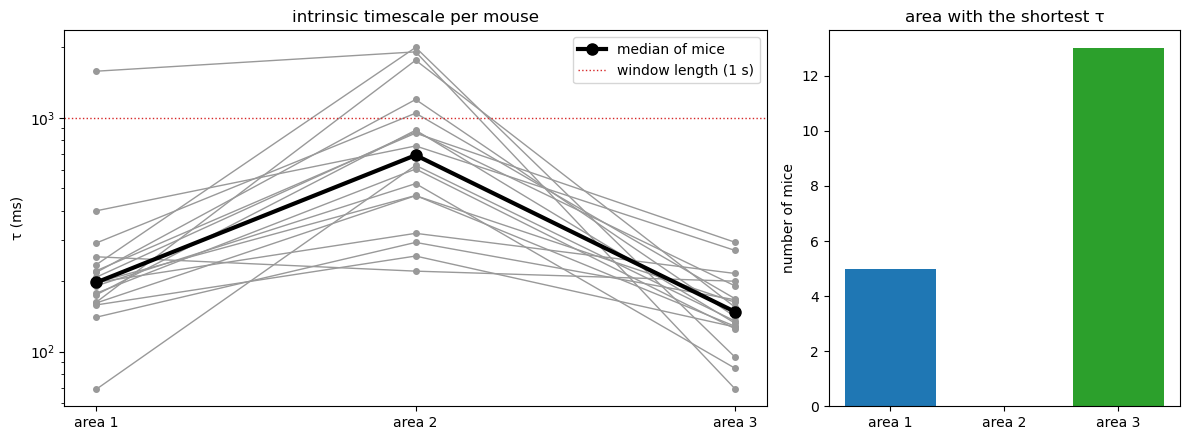

In [3]:
per_mouse, friedman, wilc = per_mouse_tests(pop, "tau_ms")
shortest = taus.idxmin(axis=1).value_counts().reindex(AREAS, fill_value=0)
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4.5), gridspec_kw=dict(width_ratios=[2, 1]))
for m, row in taus.iterrows():
    a1.plot(AREAS, row.values, "-o", color="0.6", ms=4, lw=1)
a1.plot(AREAS, taus.median().values, "-o", color="k", lw=3, ms=8, label="median of mice")
a1.axhline(1000, color="tab:red", ls=":", lw=1, label="window length (1 s)")
a1.set(yscale="log", xticks=AREAS, xticklabels=[f"area {a}" for a in AREAS], ylabel="τ (ms)", title="intrinsic timescale per mouse")
a1.legend()
a2.bar([f"area {a}" for a in AREAS], shortest.values, color=[AREA_COLORS[a] for a in AREAS])
a2.set(ylabel="number of mice", title="area with the shortest τ")
fig.tight_layout()
print("Friedman p =", f"{friedman.pvalue:.1e}")
display(wilc.style.format({"wilcoxon p": "{:.1e}"}))
taus.round(0).T

## 3. Mean and 95% CI (bootstrap over mice)

The questionnaire asks for the mean. Because area 2 has several τ values near the 2-s cap, its mean is inflated and uncertain, so the median is shown as well.

In [4]:
t_main, boot = area_bootstrap(pop, "tau_ms")
display(t_main.round(1))
print("median over mice (ms):", taus.median().round(0).to_dict())

,estimate,ci_low,ci_high,p (diff = 0)
area 1,280.2,180.9,448.9,NaN
area 2,837.2,605.0,1092.8,NaN
area 3,159.1,133.1,186.7,NaN
area 1 − area 2,-557.0,-790.9,-360.4,0.0
area 1 − area 3,121.1,18.3,299.0,0.0
area 2 − area 3,678.1,438.5,945.7,0.0


median over mice (ms): {1: 198.0, 2: 692.0, 3: 148.0}


## 4. Robustness

In [5]:
def row(t, lab):
    w31 = sps.wilcoxon(t[3], t[1]).pvalue
    return lab, {**{f"area {a} median τ (ms)": t[a].median() for a in AREAS},
                 "shortest in n mice": dict(t.idxmin(axis=1).value_counts().sort_index()),
                 "3 < 1 in n mice": int((t[3] < t[1]).sum()), "Wilcoxon p 3 vs 1": w31,
                 "Wilcoxon p 3 vs 2": sps.wilcoxon(t[3], t[2]).pvalue}

rows = dict([row(taus, "main: 1 s before stimulus, units ≥ 1 Hz")])
for w, lab in [("iti", "inter-trial interval (0.8 s before trial start)")]:
    rows.update([row(q.population_taus(units, acfs, w).pivot(index="mouse", columns="area", values="tau_ms"), lab)])
for mr in (0.5, 2.0):
    rows.update([row(q.population_taus(units, acfs, "pre1s", min_rate=mr).pivot(index="mouse", columns="area", values="tau_ms"),
                     f"1 s before stimulus, units ≥ {mr} Hz")])
good = units[(units.window == "pre1s") & (units.baseline_rate_hz >= 1) & (units.r2 > 0.5) & (units.A > 0) & (units.tau_ms < 1000)]
pu = good.groupby(["mouse", "area"]).tau_ms.median().unstack()
rows.update([row(pu, "per-unit fits (median per mouse; R² > 0.5, τ < 1 s)")])
print("units with a usable per-unit fit:", good.groupby("area").size().to_dict())
robust = pd.DataFrame(rows).T
robust

units with a usable per-unit fit: {1: 493, 2: 190, 3: 188}


,area 1 median τ (ms),area 2 median τ (ms),area 3 median τ (ms),shortest in n mice,3 < 1 in n mice,Wilcoxon p 3 vs 1,Wilcoxon p 3 vs 2
"main: 1 s before stimulus, units ≥ 1 Hz",197.614238,692.003125,148.075459,"{1: 5, 3: 13}",13,0.018234,0.000008
inter-trial interval (0.8 s before trial start),167.853924,589.581971,161.151318,"{1: 6, 3: 12}",12,0.167351,0.000008
"1 s before stimulus, units ≥ 0.5 Hz",200.424705,663.691081,152.440947,"{1: 4, 3: 14}",14,0.003365,0.000008
"1 s before stimulus, units ≥ 2.0 Hz",201.615399,745.335606,162.234482,"{1: 6, 2: 1, 3: 11}",11,0.196388,0.000053
"per-unit fits (median per mouse; R² > 0.5, τ < 1 s)",181.17822,331.280119,117.837821,"{1: 4, 3: 14}",14,0.001579,NaN


## 5. Answer for the questionnaire

In [6]:
from c2p.questionnaire import fill_pdf, record_answer, record_meta

answer = t_main.iloc[:3, :3].copy()
answer.columns = ["Mean", "CI low", "CI high"]
rows_q = [(f"{r.Mean:.0f}", f"[{r['CI low']:.0f}, {r['CI high']:.0f}]", "ms") for _, r in answer.iterrows()]
answer.to_csv(RESULTS_DIR / "q10_answer.csv")
med = taus.median()
wb = wilc["wilcoxon p (Bonferroni)"]
p_unit = min(1, 3 * robust.iloc[-1]["Wilcoxon p 3 vs 1"])
expl = (
    f"Intrinsic timescales were estimated as in Murray et al. (2014). The baseline was the 1 s before stimulus onset, "
    f"in trials where that second started after the previous trial had ended. Spikes were counted in 50-ms bins, the "
    f"autocorrelation between bins was computed across trials and averaged by lag, and an exponential decay "
    f"A(exp(-lag/tau) + B) was fitted to the mean autocorrelation of each mouse and area (units with baseline rate "
    f">= 1 Hz; median fit R2 = {pop.r2.median():.2f}). The table gives the mean tau over mice with a bootstrap CI; area 2 "
    f"contains several taus longer than the window, which inflate its mean. Area 3 had the shortest median timescale "
    f"({med[3]:.0f} ms vs {med[1]:.0f} ms in area 1 and {med[2]:.0f} ms in area 2) and was shorter than area 2 in "
    f"{int((taus[3] < taus[2]).sum())} of 18 mice (p < 0.001), but its difference from area 1 was not significant "
    f"({int((taus[3] < taus[1]).sum())} of 18 mice, paired Wilcoxon p = {wb['area 1 vs area 3']:.3f}). It was also not "
    f"significant with an inter-trial-interval baseline or with only units above 2 Hz; only separate fits per unit "
    f"separated them (p = {p_unit:.3f}). Pairwise p-values are Bonferroni-corrected for the three comparisons. Because "
    f"no area was reliably shorter than both others, I answer not enough data / no differences."
)
print(len(expl.split()), "words"); print(expl)
record_answer(10, choice=3, rows=rows_q, explanation=expl)  # 3 = not enough data / no differences
record_meta(10, confidence=4, consensus=3)
print(fill_pdf())


208 words
Intrinsic timescales were estimated as in Murray et al. (2014). The baseline was the 1 s before stimulus onset, in trials where that second started after the previous trial had ended. Spikes were counted in 50-ms bins, the autocorrelation between bins was computed across trials and averaged by lag, and an exponential decay A(exp(-lag/tau) + B) was fitted to the mean autocorrelation of each mouse and area (units with baseline rate >= 1 Hz; median fit R2 = 0.94). The table gives the mean tau over mice with a bootstrap CI; area 2 contains several taus longer than the window, which inflate its mean. Area 3 had the shortest median timescale (148 ms vs 198 ms in area 1 and 692 ms in area 2) and was shorter than area 2 in 18 of 18 mice (p < 0.001), but its difference from area 1 was not significant (13 of 18 mice, paired Wilcoxon p = 0.055). It was also not significant with an inter-trial-interval baseline or with only units above 2 Hz; only separate fits per unit separated them (p 

/home/dariosannino/con2phys/docs/questionnaire_filled.pdf


## Conclusion

**Not enough data / no differences.** Area 2 clearly has the longest timescale (~700 ms). Area 3 (~150 ms) and area 1 (~200 ms) are both shorter, but they aren't reliably different from each other:
- the main analysis gives a corrected p ≈ 0.055;
- the inter-trial-interval baseline and high-rate units show no difference;
- only per-unit fits separate them.

Because no area is reliably the shortest, the answer is "no differences". Area 3 remains the most likely candidate.
